# Лабораторная работа 2. Обратное распространение ошибки
Оспан Әсел Ғалымжанқызы · Казахский национальный университет имени аль-Фараби

На сети 2–2–2 выполните прямой проход, получите все 12 производных и сделайте один шаг обновления.
Вычисления используют PyTorch и float64. Вход, цель и веса заданы числами, поэтому загружать данные не нужно.
Для запуска блокнота выберите ядро Python с установленным PyTorch.

## 1. Исходная точка и прямой проход
Строки матриц соответствуют нейронам. В обоих слоях действует сигмоида.
Используем $E=\frac{1}{2}\sum_i (\widehat y_i-y_i)^2$.
Перед запуском запишите две предактивации скрытого слоя и сопоставьте их с выводом.

In [1]:
"""Проверка обратного распространения на сети 2–2–2."""

import torch


PARAMETER_NAMES = ("W1", "b1", "W2", "b2")


def make_example(device="cpu"):
    options = dict(dtype=torch.float64, device=device)
    parameters = {
        "W1": torch.tensor([[0.20, -0.10], [0.30, 0.05]], **options),
        "b1": torch.tensor([0.20, -0.30], **options),
        "W2": torch.tensor([[0.40, -0.20], [-0.10, 0.30]], **options),
        "b2": torch.tensor([0.10, -0.10], **options),
    }
    x = torch.tensor([1.0, 2.0], **options)
    target = torch.tensor([0.20, 0.80], **options)
    return parameters, x, target


def forward(parameters, x):
    z1 = parameters["W1"] @ x + parameters["b1"]
    h = torch.sigmoid(z1)
    z2 = parameters["W2"] @ h + parameters["b2"]
    prediction = torch.sigmoid(z2)
    return z1, h, z2, prediction


def loss_value(parameters, x, target):
    _, _, _, prediction = forward(parameters, x)
    return (prediction - target).square().sum() / 2


@torch.no_grad()
def manual_gradients(parameters, x, target):
    _, h, _, prediction = forward(parameters, x)
    delta2 = (prediction - target) * prediction * (1 - prediction)
    delta1 = (parameters["W2"].T @ delta2) * h * (1 - h)
    return {
        "W1": torch.outer(delta1, x),
        "b1": delta1,
        "W2": torch.outer(delta2, h),
        "b2": delta2,
    }


def autograd_gradients(parameters, x, target):
    leaves = {
        name: value.detach().clone().requires_grad_()
        for name, value in parameters.items()
    }
    loss_value(leaves, x, target).backward()
    return {name: value.grad for name, value in leaves.items()}


@torch.no_grad()
def central_gradients(parameters, x, target, epsilon=1e-5):
    if epsilon <= 0:
        raise ValueError("epsilon должен быть положительным")
    gradients = {}
    for name, value in parameters.items():
        gradient = torch.empty_like(value, memory_format=torch.contiguous_format)
        for index in range(value.numel()):
            offset = torch.zeros_like(value, memory_format=torch.contiguous_format)
            offset.view(-1)[index] = epsilon
            plus = dict(parameters, **{name: value + offset})
            minus = dict(parameters, **{name: value - offset})
            numerator = loss_value(plus, x, target) - loss_value(minus, x, target)
            gradient.view(-1)[index] = numerator / (2 * epsilon)
        gradients[name] = gradient
    return gradients


@torch.no_grad()
def gradient_step(parameters, gradients, eta=0.25):
    return {
        name: value - eta * gradients[name]
        for name, value in parameters.items()
    }


def flatten(parameters):
    return torch.cat([parameters[name].reshape(-1) for name in PARAMETER_NAMES])


def parameter_labels(parameters):
    labels = []
    for name in PARAMETER_NAMES:
        shape = parameters[name].shape
        if len(shape) == 2:
            labels.extend(f"{name}[{i + 1},{j + 1}]"
                          for i in range(shape[0]) for j in range(shape[1]))
        else:
            labels.extend(f"{name}[{i + 1}]" for i in range(shape[0]))
    return labels


def experiment(device="cpu"):
    parameters, x, target = make_example(device)
    manual = manual_gradients(parameters, x, target)
    automatic = autograd_gradients(parameters, x, target)
    numerical = central_gradients(parameters, x, target)
    torch.testing.assert_close(flatten(manual), flatten(automatic),
                               atol=1e-12, rtol=0)
    torch.testing.assert_close(flatten(manual), flatten(numerical),
                               atol=1e-9, rtol=0)
    return parameters, x, target, manual, automatic, numerical

In [2]:
parameters, x, target = make_example("cpu")
z1, h, z2, prediction = forward(parameters, x)
before = loss_value(parameters, x, target).item()
for label, value in zip(("z1", "h", "z2", "ŷ"), (z1, h, z2, prediction)):
    print(label, [round(t, 12) for t in value.tolist()])
print(f"E = {before:.12f}")
torch.testing.assert_close(z1, torch.tensor([0.2, 0.1], dtype=x.dtype))

z1 [0.2, 0.1]
h [0.549833997312, 0.524979187479]
z2 [0.214937761429, 0.002510356512]
ŷ [0.553528521892, 0.500627588799]
E = 0.107303128190


## 2. Три способа вычисления производных
В ручной ветви дельта выходного слоя равна $(\widehat y-y)\odot\widehat y\odot(1-\widehat y)$.
Дельта скрытого слоя использует $(W_2^\mathsf{T}\delta_2)\odot h\odot(1-h)$.
Градиенты матриц — внешние произведения дельты и входа соответствующего слоя.
Для центральной разности изменяйте одну координату при $\varepsilon=10^{-5}$.

In [3]:
from IPython.display import Markdown, SVG, display

manual = manual_gradients(parameters, x, target)
automatic = autograd_gradients(parameters, x, target)
numerical = central_gradients(parameters, x, target, epsilon=1e-5)
hand, auto, finite = map(flatten, (manual, automatic, numerical))
labels = parameter_labels(parameters)
torch.testing.assert_close(hand, auto, atol=1e-12, rtol=0)
torch.testing.assert_close(hand, finite, atol=1e-9, rtol=0)

table = ["| Параметр | Вручную | Autograd | Центральная разность |",
         "|:---|---:|---:|---:|"]
for label, a, b, c in zip(labels, hand.tolist(), auto.tolist(), finite.tolist()):
    table.append(f"| {label} | {a:+.10f} | {b:+.10f} | {c:+.10f} |")
display(Markdown("\n".join(table)))
print(f"Макс. |ручной − autograd| = {(hand - auto).abs().max().item():.3e}")
print(f"Макс. |ручной − центральная разность| = {(hand - finite).abs().max().item():.3e}")

| Параметр | Вручную | Autograd | Центральная разность |
|:---|---:|---:|---:|
| W1[1,1] | +0.0105026144 | +0.0105026144 | +0.0105026143 |
| W1[1,2] | +0.0210052287 | +0.0210052287 | +0.0210052287 |
| W1[2,1] | -0.0099567694 | -0.0099567694 | -0.0099567694 |
| W1[2,2] | -0.0199135388 | -0.0199135388 | -0.0199135388 |
| b1[1] | +0.0105026144 | +0.0105026144 | +0.0105026143 |
| b1[2] | -0.0099567694 | -0.0099567694 | -0.0099567694 |
| W2[1,1] | +0.0480385368 | +0.0480385368 | +0.0480385368 |
| W2[1,2] | +0.0458669929 | +0.0458669929 | +0.0458669929 |
| W2[2,1] | -0.0411512176 | -0.0411512176 | -0.0411512176 |
| W2[2,2] | -0.0392910094 | -0.0392910094 | -0.0392910094 |
| b2[1] | +0.0873691643 | +0.0873691643 | +0.0873691643 |
| b2[2] | -0.0748429849 | -0.0748429849 | -0.0748429849 |

Макс. |ручной − autograd| = 3.469e-18
Макс. |ручной − центральная разность| = 2.079e-12


На диаграмме значения для одного параметра слегка разнесены по горизонтали.
Высота показывает знак и значение производной. Численные допуски проверяются в предыдущей ячейке.

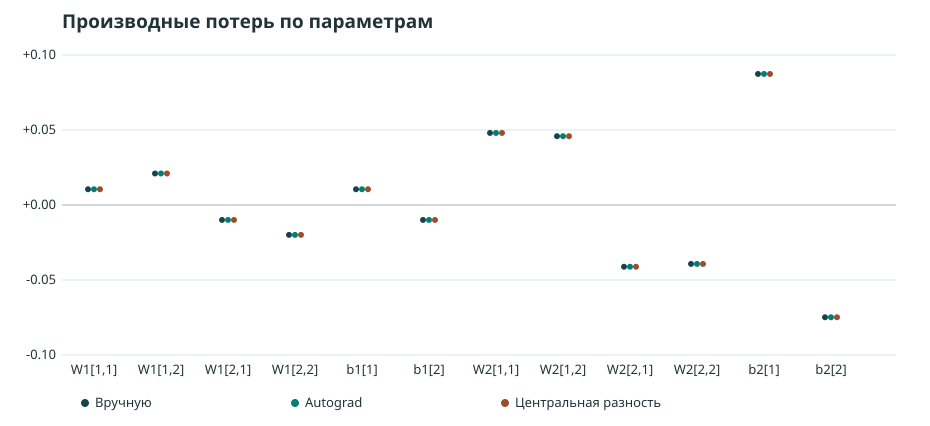

In [4]:
marks = []
for tick in (-0.1, -0.05, 0.0, 0.05, 0.1):
    yy = 205 - 1500 * tick
    grid = "#a4b1b3" if tick == 0 else "#d9e3e4"
    marks.append(f'<path d="M62 {yy} H896" stroke="{grid}"/>')
    marks.append(f'<text x="56" y="{yy+4}" text-anchor="end">{tick:+.2f}</text>')
for j, label in enumerate(labels):
    xx = 94 + 67 * j
    marks.append(f'<text x="{xx}" y="374" text-anchor="middle">{label}</text>')

methods = (("Вручную", hand, "#17444b"),
           ("Autograd", auto, "#007f70"),
           ("Центральная разность", finite, "#9b4d2d"))
for k, (label, values, color) in enumerate(methods):
    for j, value in enumerate(values.tolist()):
        xx = 94 + 67 * j + 6 * (k - 1)
        yy = 205 - 1500 * value
        marks.append(f'<circle cx="{xx}" cy="{yy:.4f}" r="3" fill="{color}"/>')
    lx = 85 + 210 * k
    marks.append(f'<circle cx="{lx}" cy="403" r="4" fill="{color}"/>')
    marks.append(f'<text x="{lx+10}" y="407">{label}</text>')

svg = (
    '<svg xmlns="http://www.w3.org/2000/svg" width="930" height="426" '
    'viewBox="0 0 930 426" font-family="sans-serif" font-size="13" fill="#203438" '
    'role="img" aria-label="Значения градиентов тремя методами">'
    '<rect width="930" height="426" fill="white"/>'
    '<text x="62" y="28" font-size="19" font-weight="bold">Производные потерь по параметрам</text>'
    + "".join(marks)
    + "</svg>"
)
display(SVG(svg))

## 3. Один шаг и повторный прогноз
Все 12 поправок рассчитываются из исходной точки. Проверьте, что новое состояние не меняет исходные тензоры.

In [5]:
original = flatten(parameters).clone()
updated = gradient_step(parameters, manual, eta=0.25)
next_prediction = forward(updated, x)[-1]
after = loss_value(updated, x, target).item()
torch.testing.assert_close(flatten(parameters), original, atol=0, rtol=0)
torch.testing.assert_close(flatten(updated), original - 0.25 * hand)
assert after < before
print("ŷ до шага:   ", prediction.tolist())
print("ŷ после шага:", next_prediction.tolist())
print(f"E до и после: {before:.12f} → {after:.12f}")
print("PyTorch", torch.__version__, "|", x.device, "|", x.dtype)

ŷ до шага:    [0.5535285218920095, 0.5006275887985256]
ŷ после шага: [0.5444252885184868, 0.5083837114338241]
E до и после: 0.107303128190 → 0.101834419564
PyTorch 2.10.0+cpu | cpu | torch.float64


## 4. Самостоятельная работа
**A.** Вручную восстановите все производные и новые параметры. Покажите два вклада в $\partial E/\partial h_1$.

**B.** Сравните максимальную абсолютную ошибку центральной разности для
$10^{-2},10^{-4},10^{-5},10^{-7},10^{-9}$. Начните с цикла ниже. Затем измените цель на $(0{,}40;0{,}60)$
и вновь вычислите три градиента из исходной точки.

**C.** Примените разные $\eta$ к одному исходному градиенту и сопоставьте потери.
Затем выполните десять шагов с пересчётом градиента на каждом шаге. Сохраните график для отчёта.

In [6]:
for epsilon in (1e-2, 1e-4, 1e-5, 1e-7, 1e-9):
    approximate = flatten(central_gradients(parameters, x, target, epsilon))
    max_error = (hand - approximate).abs().max().item()
    print(f"ε = {epsilon:.0e}: максимум |Δg| = {max_error:.3e}")

ε = 1e-02: максимум |Δg| = 1.030e-06
ε = 1e-04: максимум |Δg| = 1.030e-10
ε = 1e-05: максимум |Δg| = 2.079e-12
ε = 1e-07: максимум |Δg| = 1.601e-10
ε = 1e-09: максимум |Δg| = 1.051e-08


Методический источник — локальный «СЕМИНАР 2 Backpropagation.docx» и шаблон backprop_calculator.xlsx.
Числовой пример, код и проверочные задания подготовлены для данного учебника.